<a href="https://colab.research.google.com/github/g0h0b1/formtest/blob/main/optics_mlp_updated.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

ablation_results.csv  dbip-city-lite-2025-02.csv  pca_top20.png  sample_data
3335386 rows; 128845 cities; ['OC' 'AS' 'EU' 'NA' 'SA' 'AF']
   ip_start      ip_end continent country      region  \
1   1.0.0.0   1.0.0.255        OC      AU  Queensland   
2   1.0.1.0   1.0.3.255        AS      CN      Fujian   
3   1.0.4.0   1.0.7.255        OC      AU    Victoria   
4   1.0.8.0  1.0.15.255        AS      CN   Guangdong   
5  1.0.16.0  1.0.16.255        AS      JP       Tokyo   

                           city      lat      lon  ip_start_int  ip_end_int  \
1  AU|Queensland|South Brisbane -27.4767  153.017      16777216    16777471   
2             CN|Fujian|Wenquan  26.0998  119.297      16777472    16778239   
3      AU|Victoria|Narre Warren -38.0268  145.301      16778240    16779263   
4        CN|Guangdong|Guangzhou  23.1317  113.266      16779264    16781311   
5              JP|Tokyo|Chiyoda  35.6916  139.768      16781312    16781567   

   continent_code  country_code  region_code

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptro

                       setting             acc        macro_f1 clusters noise silhouette
            IP only, no OPTICS 0.183 +/- 0.011 0.114 +/- 0.010                          
          IP only, with OPTICS 0.434 +/- 0.008 0.424 +/- 0.006     2659  1355      0.516
     IP + geo codes, no OPTICS 0.898 +/- 0.002 0.892 +/- 0.007                          
         IP + geo, with OPTICS 0.919 +/- 0.003 0.919 +/- 0.002     2676  1339      0.532
IP + geo + coords, with OPTICS 0.968 +/- 0.004 0.968 +/- 0.004     2639  1521        0.5
  IP + geo + coords, no OPTICS 0.945 +/- 0.015 0.941 +/- 0.019                          
                 1-NN, IP only 0.486 +/- 0.007 0.486 +/- 0.008                          
                1-NN, IP + geo 0.914 +/- 0.005 0.914 +/- 0.005                          
       1-NN, IP + geo + coords 0.984 +/- 0.003 0.984 +/- 0.003                          


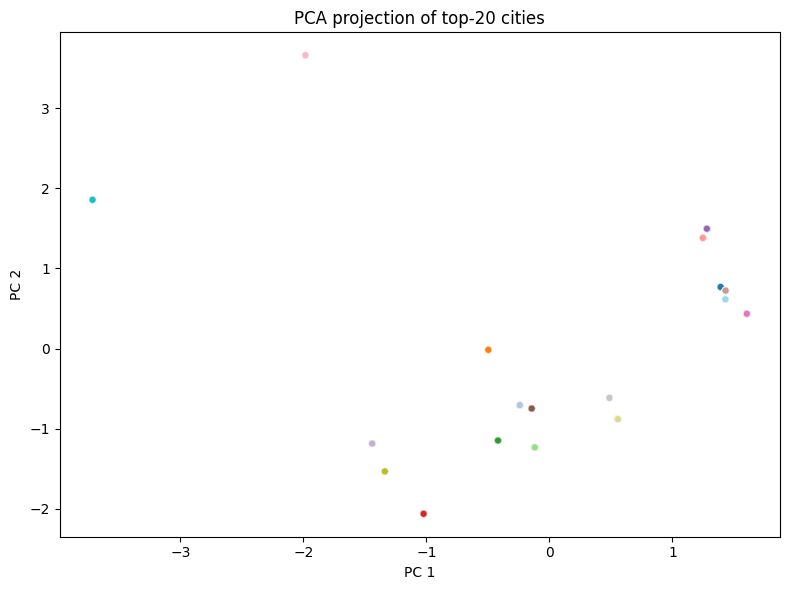

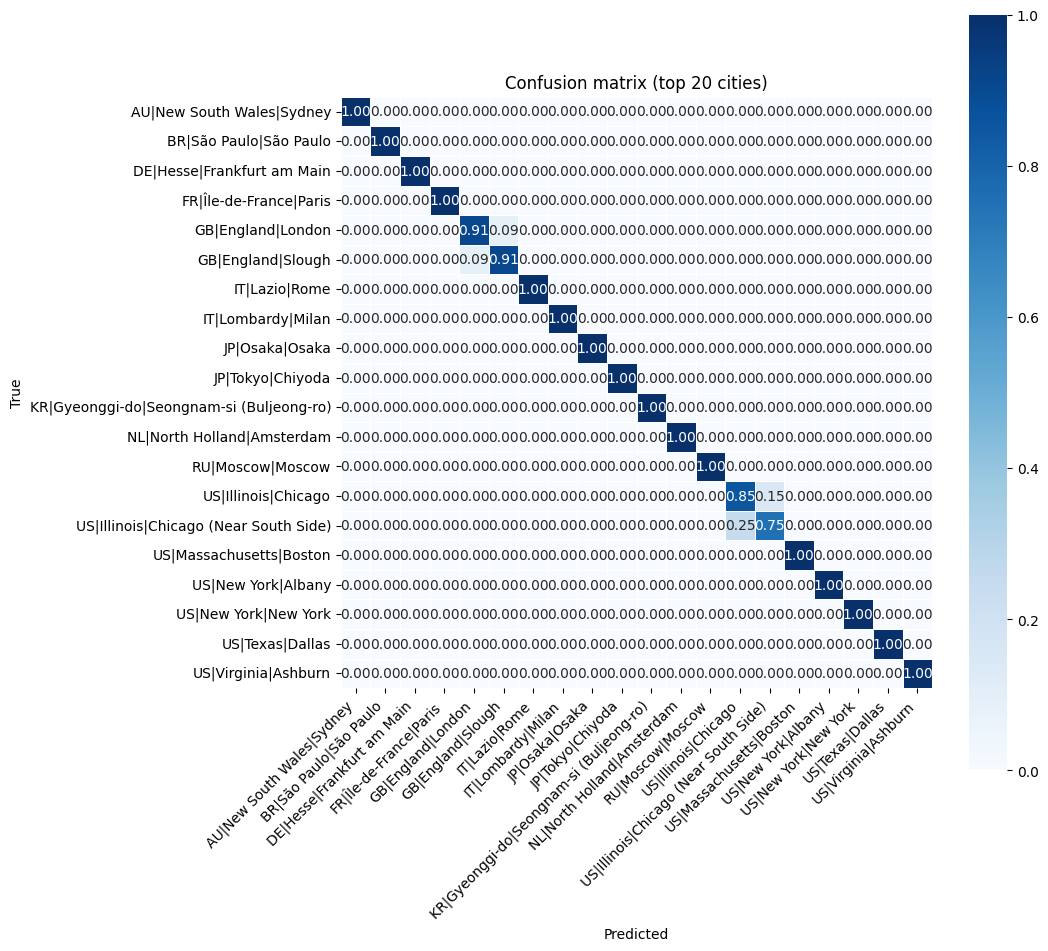

                                          precision    recall  f1-score   support

               AU|New South Wales|Sydney       1.00      1.00      1.00       325
                  BR|São Paulo|São Paulo       1.00      1.00      1.00       273
              DE|Hesse|Frankfurt am Main       1.00      1.00      1.00       286
                  FR|Île-de-France|Paris       1.00      1.00      1.00       295
                       GB|England|London       0.92      0.91      0.91       324
                       GB|England|Slough       0.91      0.91      0.91       312
                           IT|Lazio|Rome       1.00      1.00      1.00       324
                       IT|Lombardy|Milan       1.00      1.00      1.00       320
                          JP|Osaka|Osaka       1.00      1.00      1.00       319
                        JP|Tokyo|Chiyoda       1.00      1.00      1.00       297
KR|Gyeonggi-do|Seongnam-si (Buljeong-ro)       1.00      1.00      1.00       284
              N

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptro

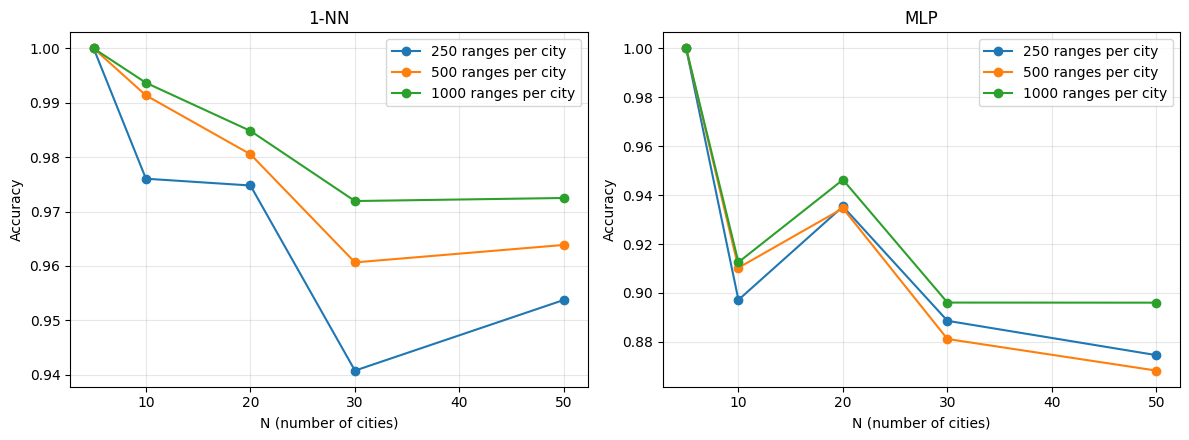

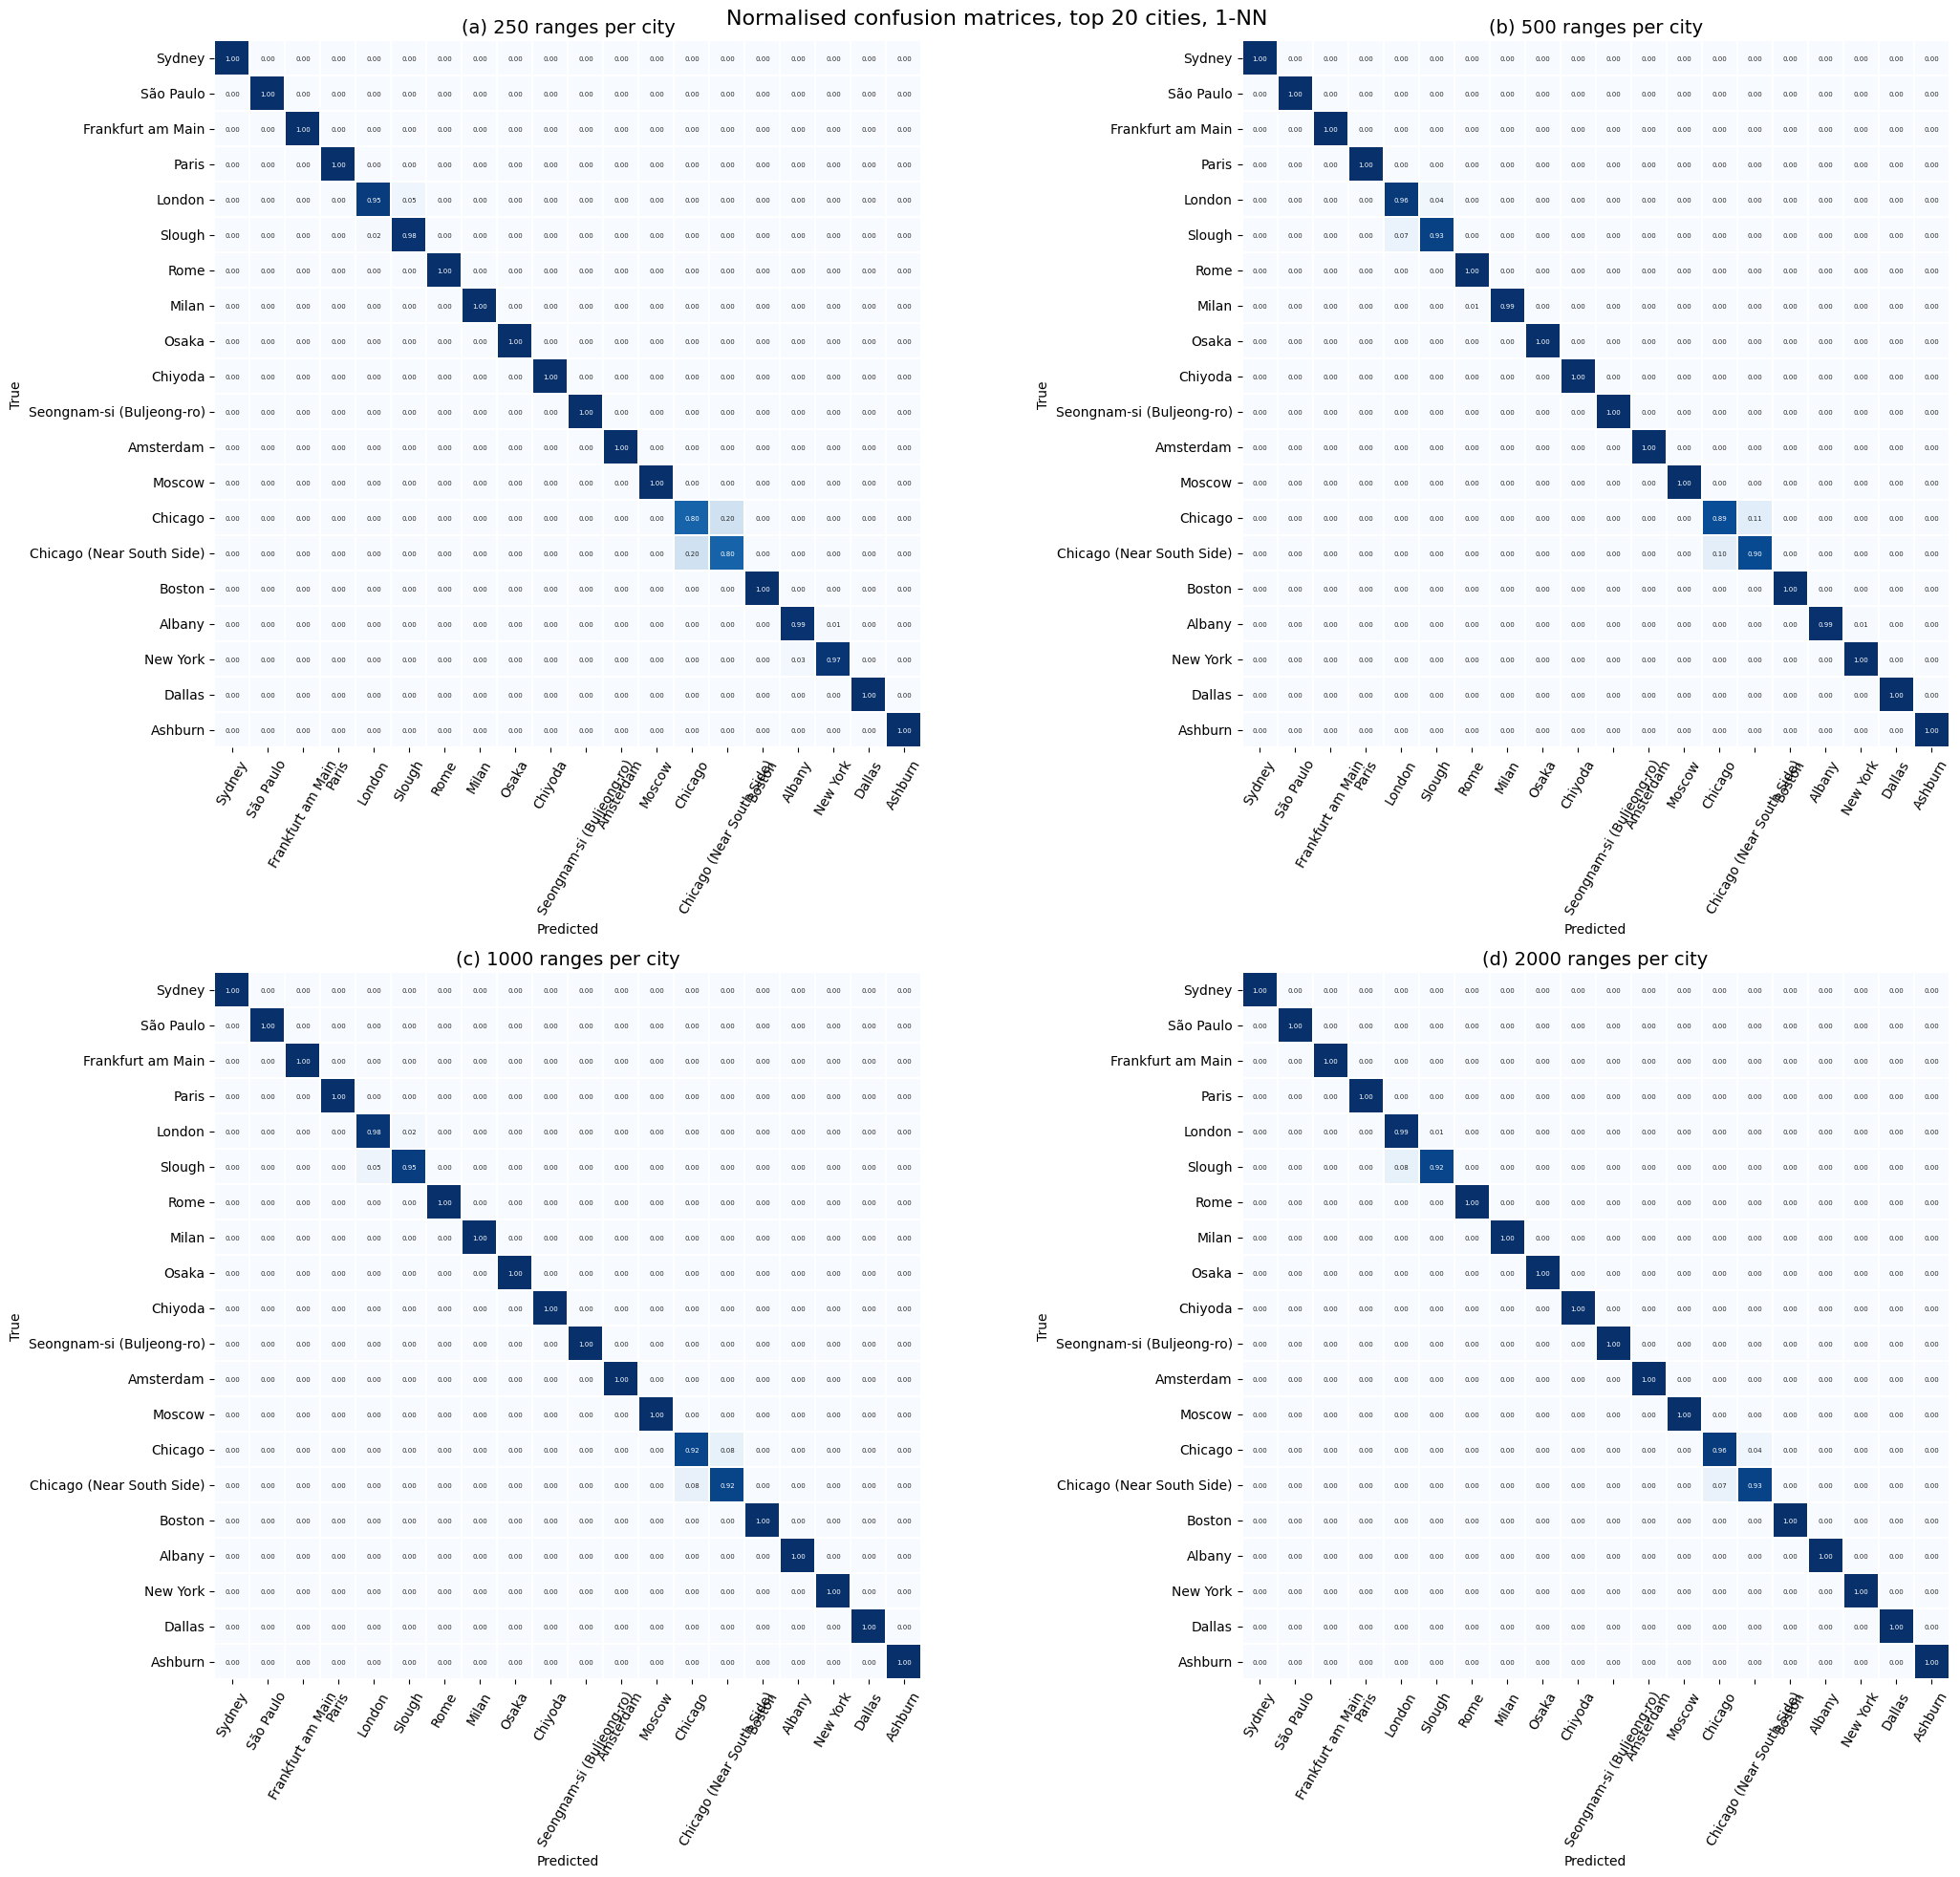

In [2]:
# Install required packages
!ls
!pip install scikit-learn matplotlib numpy pandas seaborn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import OPTICS
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import classification_report, confusion_matrix
#from sklearn.datasets import load_iris
from sklearn.neural_network import MLPClassifier
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import silhouette_score

from scipy import sparse
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import accuracy_score, f1_score

# Set random seeds for reproducibility
np.random.seed(42)

import ipaddress
import pandas as pd

cols = ["ip_start", "ip_end", "continent", "country", "region", "city", "lat", "lon"]

raw = pd.read_csv("/content/dbip-city-lite-2025-02.csv", header=None, names=cols,
                  keep_default_na=False, low_memory=False)

raw = raw[~raw.ip_start.str.contains(":")].copy()   # IPv4 فقط

raw = raw[(raw.city != "") & (raw.region != "") & (raw.country != "ZZ")].copy()
print(len(raw), "rows;", raw.city.nunique(), "cities;", raw.continent.unique())

raw["city"] = raw["country"] + "|" + raw["region"] + "|" + raw["city"]
n_city_names = raw.city.nunique()

for c in ("ip_start", "ip_end"):
    raw[c + "_int"] = raw[c].map(lambda s: int(ipaddress.IPv4Address(s)))

mapping = {}
for c in ["continent", "country", "region", "city"]:
    codes, uniq = pd.factorize(raw[c], sort=True)
    raw[c + "_code"] = codes
    mapping[c] = dict(enumerate(uniq))      # هذه خريطة أسماء المدن للجدول 4



# 1. Load your dataset
TARGET = "city_code"
IP_FEATURES   = ["ip_start_int", "ip_end_int"]
GEO_FEATURES  = ["continent_code", "country_code", "region_code"]
COORD_FEATURES = ["lat", "lon"]

TOP_N = 20
SEEDS = [0, 1, 2, 3, 4]
OPTICS_PARAMS = dict(min_samples=3, xi=0.0005, min_cluster_size=2)

TABLE3_CAPS = [250, 500, 1000]
FIG6_NS = [5, 10, 20, 30, 50]
FIG6_CAPS = [250, 500, 1000]
FIG6_MODELS = ["knn", "mlp"]
FIG6_SEEDS = [0, 1, 2]
FIG7_CAPS = [250, 500, 1000, 2000]
FIG7_MODEL = "knn"

df = raw
id_to_name = mapping["city"]
IP, GEO, COORD = IP_FEATURES, GEO_FEATURES, COORD_FEATURES
ALL = IP + GEO + COORD
CAP = 1000          # أقصى عدد صفوف لكل مدينة
print(raw.head())

print(raw[TARGET].value_counts().head(20))

# فحص التداخل الجغرافي بين فئات متشابهة
pairs = [("US|Illinois|Chicago", "US|Illinois|Chicago (Near South Side)"),
         ("GB|England|London", "GB|England|Slough")]
for a, b in pairs:
    ca = df[df.city == a][["lat", "lon"]].mean(); cb = df[df.city == b][["lat", "lon"]].mean()
    dlat = ca["lat"] - cb["lat"]; dlon = ca["lon"] - cb["lon"]
    km = ((dlat * 111) ** 2 + (dlon * 111 * np.cos(np.radians(ca["lat"]))) ** 2) ** 0.5
    print(a, "|", b, "| فرق lat:", round(dlat, 3), "فرق lon:", round(dlon, 3),
          "| المسافة التقريبية بين المركزين (كم):", round(km, 1))


def optics_fit_assign(Xtr, Xte, params):
    opt = OPTICS(**params).fit(Xtr)            # التجميع على التدريب فقط
    tr_labels = opt.labels_.copy()             # -1 = ضوضاء، تبقى مجموعة مستقلة
    nn = NearestNeighbors(n_neighbors=1).fit(Xtr)
    idx = nn.kneighbors(Xte, return_distance=False)[:, 0]
    return tr_labels, tr_labels[idx], int((tr_labels == -1).sum())


def run(df, features, use_cluster, seed, model="mlp", top_n=None, cap=None):
    top_n = TOP_N if top_n is None else top_n
    cap = CAP if cap is None else cap

    top = df[TARGET].value_counts().head(top_n).index
    d = df[df[TARGET].isin(top)]                                       # 1) يعرّف d أولاً
    d = d.sample(frac=1, random_state=0).groupby(TARGET).head(cap)     # 2) ثم يحدد الحد الأقصى لكل مدينة
    X = d[features].to_numpy(dtype=float)
    y = d[TARGET].to_numpy()
    from sklearn.model_selection import GroupShuffleSplit
    groups = d["ip_start_int"].to_numpy() // 65536
    gss = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=seed)
    tr, te = next(gss.split(X, y, groups))
    Xtr, Xte, ytr, yte = X[tr], X[te], y[tr], y[te]

    sc = StandardScaler().fit(Xtr)
    Xtr_s, Xte_s = sc.transform(Xtr), sc.transform(Xte)

    info = {"n_rows": len(d), "n_train": len(Xtr)}

    if use_cluster:
        trc, tec, n_noise = optics_fit_assign(Xtr_s, Xte_s, OPTICS_PARAMS)
        enc = OneHotEncoder(handle_unknown="ignore").fit(trc.reshape(-1, 1))
        Xtr_f = sparse.hstack([sparse.csr_matrix(Xtr_s), enc.transform(trc.reshape(-1, 1))]).tocsr()
        Xte_f = sparse.hstack([sparse.csr_matrix(Xte_s), enc.transform(tec.reshape(-1, 1))]).tocsr()
        info.update(n_clusters=len(set(trc)), n_noise=n_noise)
        if info["n_clusters"] > 1:
            info["silhouette"] = silhouette_score(Xtr_s, trc,
                                    sample_size=min(10000, len(Xtr_s)), random_state=seed)
    else:
        Xtr_f, Xte_f = Xtr_s, Xte_s

    if model == "knn":
      from sklearn.neighbors import KNeighborsClassifier
      clf = KNeighborsClassifier(n_neighbors=1).fit(Xtr_f, ytr)
    else:
        clf = MLPClassifier(hidden_layer_sizes=(100,), max_iter=300, random_state=seed).fit(Xtr_f, ytr)
    p = clf.predict(Xte_f)

    return accuracy_score(yte, p), f1_score(yte, p, average="macro", zero_division=0), info, yte, p

settings = [
    ("IP only, no OPTICS",        IP_FEATURES, False),
    ("IP only, with OPTICS",      IP_FEATURES, True),
    ("IP + geo codes, no OPTICS", IP_FEATURES + GEO_FEATURES, False),
    ("IP + geo, with OPTICS",     IP_FEATURES + GEO_FEATURES, True),
    ("IP + geo + coords, with OPTICS", IP_FEATURES + GEO_FEATURES + COORD_FEATURES, True),
    ("IP + geo + coords, no OPTICS", IP_FEATURES + GEO_FEATURES + COORD_FEATURES, False),
]

rows = []

# (أ) صفوف MLP: مع OPTICS وبدونه
for name, feats, uc in settings:
    r = [run(df, feats, uc, s) for s in SEEDS]
    accs = [x[0] for x in r]; f1s = [x[1] for x in r]; info = r[0][2]
    rows.append(dict(setting=name,
                     acc=f"{np.mean(accs):.3f} +/- {np.std(accs):.3f}",
                     macro_f1=f"{np.mean(f1s):.3f} +/- {np.std(f1s):.3f}",
                     clusters=info.get("n_clusters", ""),
                     noise=info.get("n_noise", ""),
                     silhouette=round(info["silhouette"], 3) if "silhouette" in info else ""))

# (ب) صفوف 1-NN
for name, feats in [("1-NN, IP only", IP_FEATURES),
                    ("1-NN, IP + geo", IP_FEATURES + GEO_FEATURES),
                    ("1-NN, IP + geo + coords", IP_FEATURES + GEO_FEATURES + COORD_FEATURES)]:
    r = [run(df, feats, False, s, model="knn") for s in SEEDS]
    rows.append(dict(setting=name,
                     acc=f"{np.mean([x[0] for x in r]):.3f} +/- {np.std([x[0] for x in r]):.3f}",
                     macro_f1=f"{np.mean([x[1] for x in r]):.3f} +/- {np.std([x[1] for x in r]):.3f}",
                     clusters="", noise="", silhouette=""))

results = pd.DataFrame(rows)
print(results.to_string(index=False))
results.to_csv("ablation_results.csv", index=False)
MODEL_SPECS = {
    "knn":        dict(use_cluster=False, model="knn", label="1-NN"),
    "mlp":        dict(use_cluster=False, model="mlp", label="MLP"),
    "mlp_optics": dict(use_cluster=True,  model="mlp", label="MLP + OPTICS"),
}
def call(mk, feats, seed, **kw):
    sp = MODEL_SPECS[mk]
    return run(df, feats, sp["use_cluster"], seed, model=sp["model"], **kw)




top = df[TARGET].value_counts().head(TOP_N).index
d = df[df[TARGET].isin(top)]
d = d.sample(frac=1, random_state=0).groupby(TARGET).head(CAP)



Xp = StandardScaler().fit_transform(d[GEO_FEATURES + COORD_FEATURES].to_numpy(dtype=float))

Z = PCA(n_components=2).fit_transform(Xp)
plt.figure(figsize=(8, 6))
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=d[TARGET].astype(str).values,
                palette="tab20", s=25, alpha=0.7, legend=False)
plt.title("PCA projection of top-20 cities")
plt.xlabel("PC 1"); plt.ylabel("PC 2")
plt.tight_layout(); plt.savefig("pca_top20.png", dpi=300); plt.show()

_, _, _, yte, p = run(df, IP_FEATURES + GEO_FEATURES + COORD_FEATURES, True, 0)
labels = np.unique(yte)
cm = confusion_matrix(yte, p, labels=labels, normalize="true")

# إذا عندك خريطة الترميز: id_to_name = {1321: "Paris", ...}
names = [str(id_to_name.get(l, l)) for l in labels] if "id_to_name" in globals() else [str(l) for l in labels]
plt.figure(figsize=(11, 10))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=names, yticklabels=names, linewidths=0.5, square=True)
plt.xlabel("Predicted"); plt.ylabel("True")
plt.title("Confusion matrix (top 20 cities)")
plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()

from sklearn.metrics import classification_report
print(classification_report(yte, p, labels=labels, target_names=names, zero_division=0))
A = set(map(tuple, df[df.city == "GB|England|London"][["lat","lon"]].round(3).values))
B = set(map(tuple, df[df.city == "GB|England|Slough"][["lat","lon"]].round(3).values))
print(len(A), len(B), "إحداثيات مشتركة:", len(A & B))

# تقرير 1-NN بالإحداثيات (البذرة 0)
_, _, _, yte1, p1 = run(df, IP_FEATURES + GEO_FEATURES + COORD_FEATURES, False, 0, model="knn")
labels1 = np.unique(yte1)
names1 = [str(id_to_name.get(l, l)) for l in labels1]
print(classification_report(yte1, p1, labels=labels1, target_names=names1, zero_division=0))

# هل تشترك فئتا Chicago في إحداثيات؟
A = set(map(tuple, df[df.city == "US|Illinois|Chicago"][["lat", "lon"]].round(3).values))
B = set(map(tuple, df[df.city == "US|Illinois|Chicago (Near South Side)"][["lat", "lon"]].round(3).values))
print(len(A), len(B), "إحداثيات مشتركة:", len(A & B))


t1 = pd.DataFrame({
    "Item": ["Database", "IPv4 ranges used", "Distinct city names", "Distinct cities (country|region|city)",
             "Distinct regions", "Distinct countries", "Continents",
             "Cities kept (top N)", "Max ranges per city (cap)"],
    "Value": ["DB-IP City Lite (February 2025)", len(df), n_city_names, df.city.nunique(),
              df.groupby(["country", "region"]).ngroups, df.country.nunique(),
              ", ".join(sorted(df.continent.unique())), TOP_N, CAP]})
print(t1.to_string(index=False)); t1.to_csv("table1_dataset.csv", index=False)


rows3 = []
for cap in TABLE3_CAPS:
    acc, f1, info, _, _ = call("mlp_optics", ALL, 0, cap=cap)
    rows3.append(dict(ranges_per_city=cap, rows_used=info["n_rows"], train_rows=info["n_train"],
                      clusters=info["n_clusters"], noise_points=info["n_noise"],
                      noise_pct=round(100 * info["n_noise"] / info["n_train"], 1),
                      silhouette=round(info.get("silhouette", float("nan")), 3)))
    print(rows3[-1], flush=True)
t3 = pd.DataFrame(rows3); t3.to_csv("table3_clusters_vs_cap.csv", index=False)
print(t3.to_string(index=False))


parts = []
for mk in ["mlp_optics", "knn"]:
    _, _, _, yte, p = call(mk, ALL, 0)
    labels = np.unique(yte)
    rep = classification_report(yte, p, labels=labels, zero_division=0, output_dict=True,
                                target_names=[str(id_to_name[l]) for l in labels])
    r = pd.DataFrame(rep).T[["precision", "recall", "f1-score", "support"]].round(2)
    r.columns = [f"{MODEL_SPECS[mk]['label']} {c}" for c in r.columns]
    parts.append(r)
t4 = pd.concat(parts, axis=1); t4.to_csv("table4_per_city.csv")
print(t4.to_string())


fig, axes = plt.subplots(1, len(FIG6_MODELS), figsize=(6 * len(FIG6_MODELS), 4.5), squeeze=False)
store = []
for ax, mk in zip(axes[0], FIG6_MODELS):
    for cap in FIG6_CAPS:
        accs = []
        for n in FIG6_NS:
            accs.append(np.mean([call(mk, ALL, s, top_n=n, cap=cap)[0] for s in FIG6_SEEDS]))
            store.append(dict(model=MODEL_SPECS[mk]["label"], ranges_per_city=cap, N=n, accuracy=round(accs[-1], 3)))
        ax.plot(FIG6_NS, accs, marker="o", label=f"{cap} ranges per city")
    ax.set_title(MODEL_SPECS[mk]["label"]); ax.set_xlabel("N (number of cities)")
    ax.set_ylabel("Accuracy"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.savefig("fig6_accuracy_vs_N.png", dpi=300); plt.show()
pd.DataFrame(store).to_csv("fig6_values.csv", index=False)


fig, axes = plt.subplots(2, 2, figsize=(22, 20))
for i, (ax, cap) in enumerate(zip(axes.ravel(), FIG7_CAPS)):
    _, _, _, yte, p = call(FIG7_MODEL, ALL, 0, cap=cap)
    labels = np.unique(yte)
    cm = confusion_matrix(yte, p, labels=labels, normalize="true")
    short = [str(id_to_name[l]).split("|")[-1] for l in labels]
    sns.heatmap(cm, ax=ax, annot=True, fmt=".2f", annot_kws={"size": 5}, cmap="Blues",
                xticklabels=short, yticklabels=short, cbar=False, square=True, linewidths=0.3)
    ax.set_title(f"({chr(97 + i)}) {cap} ranges per city", fontsize=14)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.tick_params(axis="x", rotation=60)
plt.suptitle(f"Normalised confusion matrices, top {TOP_N} cities, {MODEL_SPECS[FIG7_MODEL]['label']}", fontsize=16)
plt.tight_layout(); plt.savefig("fig7_confusion_matrices.png", dpi=300); plt.show()





